Дан набор (https://disk.yandex.ru/d/hUY1bgbXM8gAIw) изображений размером 32×32 пикселя, разбитых на 5 классов: самолёт, автомобиль, птица, кот, олень.

Ваша задача — обучить модель глубокого обучения (CNN) с нуля (без использования предобученных моделей и трансферного обучения) и предсказать классы для тестового набора изображений.

In [1]:
import logging
from datetime import datetime
from pathlib import Path
from typing import Final, Optional, TypedDict

import numpy as np
import matplotlib.pyplot as plt
import mlflow
import pandas as pd
import torch
from mlflow.models import infer_signature, ModelSignature
from mlflow.types.schema import Schema, TensorSpec
from sklearn.model_selection import train_test_split
from torch import cuda, nn, Tensor
from torch.utils.data import DataLoader, Dataset
from torchcodec.decoders import decode_image
from torchvision.transforms import v2


mlflow_logger = logging.getLogger("mlflow")
mlflow_logger.setLevel(logging.INFO)

In [2]:
device = torch.device('cuda' if cuda.is_available() else 'cpu')
is_bf16_available = 'Да' if cuda.is_bf16_supported() else 'Нет'
print(f"Используем устройство {device}")
print(f"BF16 поддерживается: {is_bf16_available}")

Используем устройство cpu
BF16 поддерживается: Нет


Напишем свой класс `ImageDataset` для работы с датасетом через API PyTorch:

In [3]:
class ImageDataset(Dataset):
    """
    Обертка над датасетом для его использования в обучении нейросетей на PyTorch.

    Parameters:
        annotations_file: Путь к файл с разметкой.
        img_dir: Путь к выборке
        transform: Аугментационный пайплайн
    """
    def __init__(self, annotations_file: Path, img_dir: Path, transform: Optional[v2.Compose] = None):
        self.img_labels = pd.read_csv(annotations_file)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self) -> int:
        return len(self.img_labels)

    def __getitem__(self, idx: int) -> tuple[Tensor, str]:
        img_path = Path(self.img_dir / self.img_labels.iloc[idx, 0])
        image = decode_image(img_path) / 255.0
        if self.transform is not None:
            image = self.transform(image)
        label = self.img_labels.iloc[idx, 1]
        return image, label


class SubmitDataset(Dataset):
    """
    Обертка над данными для сабмита.

    Parameters:
        img_dir: Путь к выборке
    """
    def __init__(self, annotations_file: Path, img_dir: Path):
        df = pd.read_csv(annotations_file, header=None)
        self.image_files = tuple(f for f in df[0])
        self.img_dir = img_dir
        assert len(self.image_files) == 2424

    def __len__(self) -> int:
        return len(self.image_files)

    def __getitem__(self, idx: int) -> tuple[str, Tensor]:
        img_path = self.image_files[idx]
        image = decode_image(self.img_dir / img_path) / 255
        return img_path, image


class EpochTrainMetrics(TypedDict):
    """Метрики эпохи обучения на трейне."""
    train_loss: float
    train_accuracy: float


class EpochValMetrics(TypedDict):
    """Метрики эпохи обучения на валидации."""
    val_loss: float
    val_accuracy: float


class MlflowEpochMetrics(EpochTrainMetrics, EpochValMetrics):
    """Метрики эпохи, логирующиеся Mlflow."""
    pass


class AdamWConfig(TypedDict):
    """
    Типизирует гиперпараметры оптимизатора AdamW.

    Для использования в оптимизаторе - распаковать 
    объект через double star expression
    """
    lr: float


class HyperParams(TypedDict):
    """Гиперпараметры для логирования в Mlflow."""
    epochs: int
    learning_rate: float
    batch_size: int
    optimizer: str

# Подготовка датасета

Разобьем обучающую выборку на обучающую и тестовую (валидационную) выборки в соотношении $7:3$:

In [4]:
dataset_path = Path("dataset")
dataset_data_path = dataset_path / 'train'
dataset_labels_path = dataset_path / 'train.csv'

In [5]:
dataset = pd.read_csv(dataset_labels_path)
dataset.head(3)

,file_name,class
0,n03365231_2651.png,airplane
1,cifar10-train-32411.png,airplane
2,n04308273_5668.png,airplane


In [6]:
class_names = dataset["class"].unique()
TARGETS: Final = {label: i for i, label in enumerate(class_names)}
LABELS: Final = {i: label for i, label in enumerate(class_names)}

dataset["target"] = dataset["class"].replace(TARGETS)

In [8]:
train_labels_path = dataset_path / "train_train.csv"
val_labels_path = dataset_path / "train_valid.csv"

X, y  = dataset["file_name"], dataset["target"]
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, train_size=0.8, stratify=y, random_state=42
)
print(f"Размер train: {len(X_train)}")
print(f"Размер valid: {len(X_valid)}")
pd.concat([X_train, y_train], axis=1).to_csv(train_labels_path, index=False)
pd.concat([X_valid, y_valid], axis=1).to_csv(val_labels_path, index=False)

Размер train: 4000
Размер valid: 1000


# Обучение модели

## Просмотр изображения из датасета

Просмотрим изображение из датасета:

torch.Size([3, 32, 32])


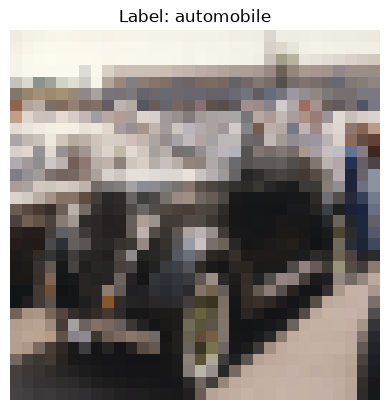

In [10]:
clear_training_data = ImageDataset(train_labels_path, dataset_data_path)
clear_train_dataloader = DataLoader(clear_training_data)

img, label = clear_train_dataloader.dataset[0]
print(img.shape)
# permute() нужен, т.к. изображение - тензор 3x32x32,
# а plt.imshow() принимает массивы размеров 32x32x3
plt.imshow(img.squeeze().permute(1, 2, 0))
plt.axis("off")
plt.title(f"Label: {LABELS[label]}")
plt.show()

## Процесс обучения

In [12]:
BATCH_SIZE: Final = 32

train_transform = v2.Compose([
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandomRotation(10),
    v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    v2.RandomErasing(p=0.2, scale=(0.02, 0.2), value='random'),
])
training_data = ImageDataset(train_labels_path, dataset_data_path, train_transform)
train_dataloader = DataLoader(training_data, batch_size=BATCH_SIZE, shuffle=True)
validating_data = ImageDataset(val_labels_path, dataset_data_path)
val_dataloader = DataLoader(validating_data, batch_size=BATCH_SIZE, shuffle=True)

Напишем цикл обучения и цикл валидации:

In [13]:
def train_loop(dataloader: DataLoader, model: nn.Module, loss_fn, optimizer, device) -> EpochTrainMetrics:
    model.train()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    train_loss = 0.0
    correct = 0
    
    for batch_idx, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)
        batch_size = X.size(0)
        pred = model(X)
        loss = loss_fn(pred, y)
        
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        train_loss += loss.item() * batch_size
        correct += (pred.argmax(1) == y).sum().item()

    epoch_loss = train_loss / num_batches
    epoch_acc = correct / size
    return EpochTrainMetrics(
        train_loss=epoch_loss,
        train_accuracy=epoch_acc
    )


def val_loop(dataloader: DataLoader, model: nn.Module, loss_fn, device) -> EpochValMetrics:
    model.eval()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    val_loss = 0.0
    correct = 0
    
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            val_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).sum().item()

    val_loss /= num_batches
    val_acc = correct / size
    return EpochValMetrics(
        val_loss=val_loss,
        val_accuracy=val_acc
    )

Объявляем архитектуру нашей CNN:

In [20]:
class ResConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, stride: int = 1, **kwargs):
        super().__init__()
        
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        identity = self.shortcut(x)

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        out += identity
        out = self.relu(out)
        return out


model = nn.Sequential(
    ResConv(3, 16, kernel_size=3, padding=1, bias=False),
    nn.MaxPool2d(2),
    ResConv(16, 32, kernel_size=3, padding=1, bias=False),
    nn.MaxPool2d(2),
    ResConv(32, 64, kernel_size=3, padding=1, bias=False),
    nn.Flatten(),
    
    nn.Linear(8*8*64, 128),
    nn.ReLU(),
    nn.Linear(128, 5)
).to(device)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Количество обучаемых параметров: {trainable_params}")

Количество обучаемых параметров: 600197


Запускаем цикл обучения:

In [15]:
input_example = torch.zeros(2, 3, 32, 32).cpu().numpy()

mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("CV_LW01")
mlflow.config.enable_system_metrics_logging()
mlflow.config.set_system_metrics_sampling_interval(1)

In [17]:
EPOCHS: Final = 150

loss_fn = nn.CrossEntropyLoss()
optimizer_config = AdamWConfig(lr=1e-4)
optimizer = torch.optim.AdamW(model.parameters(), **optimizer_config)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)


params = HyperParams(
    epochs=EPOCHS,
    learning_rate=optimizer_config["lr"],
    batch_size=BATCH_SIZE,
    optimizer="AdamW",
)
dt_now = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
with mlflow.start_run(run_name=dt_now) as run:
    try: 
        mlflow.log_params(params)
        for epoch in range(EPOCHS):
            print(f"Epoch {epoch}: Training...")
            train_metrics = train_loop(train_dataloader, model, loss_fn, optimizer, device)
            print(f"Epoch {epoch}: Validating...")
            val_metrics = val_loop(val_dataloader, model, loss_fn, device)
            scheduler.step()
    
            mlflow.log_metrics(
                MlflowEpochMetrics(**train_metrics, **val_metrics),
                step=epoch
            )
                  
        model_info = mlflow.pytorch.log_model(model, input_example=input_example, name="final_model")
        print("Done!")
    except KeyboardInterrupt:
        model_info = mlflow.pytorch.log_model(model, input_example=input_example, name="manual_interrupt")
        print("Обучение прервано :(")

2026/11/17 12:18:23 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/17 12:18:23 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.


Epoch 0: Training...
Epoch 0: Validating...
Epoch 1: Training...
Epoch 1: Validating...
Epoch 2: Training...
Epoch 2: Validating...
Epoch 3: Training...
Epoch 3: Validating...
Epoch 4: Training...
Epoch 4: Validating...
Epoch 5: Training...
Epoch 5: Validating...
Epoch 6: Training...
Epoch 6: Validating...
Epoch 7: Training...
Epoch 7: Validating...
Epoch 8: Training...
Epoch 8: Validating...
Epoch 9: Training...
Epoch 9: Validating...
Epoch 10: Training...
Epoch 10: Validating...
Epoch 11: Training...
Epoch 11: Validating...
Epoch 12: Training...
Epoch 12: Validating...
Epoch 13: Training...
Epoch 13: Validating...
Epoch 14: Training...
Epoch 14: Validating...
Epoch 15: Training...
Epoch 15: Validating...
Epoch 16: Training...
Epoch 16: Validating...
Epoch 17: Training...
Epoch 17: Validating...
Epoch 18: Training...
Epoch 18: Validating...
Epoch 19: Training...
Epoch 19: Validating...
Epoch 20: Training...
Epoch 20: Validating...
Epoch 21: Training...
Epoch 21: Validating...
Epoch 22

2026/11/17 12:29:33 WARNING mlflow.utils.requirements_utils: Found torch version (2.15.0+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.15.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/11/17 12:29:54 WARNING mlflow.utils.requirements_utils: Found torch version (2.15.0+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.15.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/11/17 12:29:54 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Обучение прервано :(


2026/11/17 12:30:01 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/17 12:30:01 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


🏃 View run 2026-11-17 12:18:21 at: http://localhost:5000/#/experiments/6/runs/24c0b29df5864a64ba401e35090ca9a3
🧪 View experiment at: http://localhost:5000/#/experiments/6


In [18]:
weights_path = Path('weights')
weights_path.mkdir(exist_ok=True)
torch.save(model.state_dict(), weights_path / 'model_weights.pth')

In [19]:
submit_data_path = dataset_path / 'test'
submit_dataset = SubmitDataset('_yandex_submit_cv1.csv', submit_data_path)
submit_dataloader = DataLoader(submit_dataset, shuffle=False)

model.eval()
with torch.no_grad():
    with open("submit.csv", "w", encoding="utf-8") as submit_file:
        for img_paths, images in submit_dataloader:
            pred = torch.argmax(model(images)).item()
            pred_label = LABELS[pred]
            img_path = img_paths[0]
            submit_file.write(f"{img_path},{pred_label}\n")